In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned sales dataset
df = pd.read_csv("cleaned_sales_data.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (317, 11)


,Order_ID,Order_Date,Customer_ID,Product,Category,Quantity,Unit_Price,Region,Payment_Method,Revenue,Month
0,ORD0001,2026-01-25,CUST0068,Laptop Stand,Accessories,1,730,Central,Credit Card,730,2026-01
1,ORD0002,2026-07-31,CUST0035,Keyboard,Accessories,3,1130,Central,Wallet,3390,2026-07
2,ORD0003,2026-06-28,CUST0069,USB-C Hub,Accessories,1,1640,East,UPI,1640,2026-06
3,ORD0004,2026-04-30,CUST0033,Laptop Stand,Accessories,5,950,East,Debit Card,4750,2026-04
4,ORD0005,2026-04-29,CUST0025,Notebook Pack,Stationery,2,240,Central,Debit Card,480,2026-04


In [5]:

# 1. Check missing values
print("Missing values in each column:")
display(df.isnull().sum())

# 2. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 3. Check data types
print("Column data types:")
display(df.dtypes)

# 4. Check basic statistics
print("Basic statistics:")
display(df.describe())


Missing values in each column:


Order_ID          0
Order_Date        0
Customer_ID       0
Product           0
Category          0
Quantity          0
Unit_Price        0
Region            0
Payment_Method    0
Revenue           0
Month             0
dtype: int64

Duplicate rows: 0
Column data types:


Order_ID            str
Order_Date          str
Customer_ID         str
Product             str
Category            str
Quantity          int64
Unit_Price        int64
Region              str
Payment_Method      str
Revenue           int64
Month               str
dtype: object

Basic statistics:


,Quantity,Unit_Price,Revenue
count,317.000000,317.000000,317.000000
mean,1.958991,2516.025237,4696.782334
std,1.150766,3300.550679,7361.191367
min,1.000000,220.000000,220.000000
25%,1.000000,730.000000,950.000000
50%,2.000000,1060.000000,2140.000000
75%,3.000000,2380.000000,4680.000000
max,5.000000,13090.000000,57250.000000


In [6]:

# 1. Check missing values
print("Missing values in each column:")
display(df.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check column data types
print("\nColumn data types:")
display(df.dtypes)

# 4. Basic statistical summary
print("\nBasic statistics:")
display(df.describe())

# 5. Check unknown values in important columns
for col in ["Region", "Payment_Method", "Product", "Category", "Month"]:
    print(f"\nUnknown or blank values in {col}:")
    print(df[col].astype("string").str.strip().str.lower()
          .isin(["unknown", ""]).sum())


Missing values in each column:


Order_ID          0
Order_Date        0
Customer_ID       0
Product           0
Category          0
Quantity          0
Unit_Price        0
Region            0
Payment_Method    0
Revenue           0
Month             0
dtype: int64


Duplicate rows: 0

Column data types:


Order_ID            str
Order_Date          str
Customer_ID         str
Product             str
Category            str
Quantity          int64
Unit_Price        int64
Region              str
Payment_Method      str
Revenue           int64
Month               str
dtype: object


Basic statistics:


,Quantity,Unit_Price,Revenue
count,317.000000,317.000000,317.000000
mean,1.958991,2516.025237,4696.782334
std,1.150766,3300.550679,7361.191367
min,1.000000,220.000000,220.000000
25%,1.000000,730.000000,950.000000
50%,2.000000,1060.000000,2140.000000
75%,3.000000,2380.000000,4680.000000
max,5.000000,13090.000000,57250.000000



Unknown or blank values in Region:
1

Unknown or blank values in Payment_Method:
1

Unknown or blank values in Product:
0

Unknown or blank values in Category:
0

Unknown or blank values in Month:
0


In [7]:

# Calculate key business KPIs

total_revenue = df["Revenue"].sum()
total_orders = df["Order_ID"].nunique()
units_sold = df["Quantity"].sum()
average_order_value = total_revenue / total_orders

print("===== SALES PERFORMANCE KPIs =====")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Distinct Orders: {total_orders}")
print(f"Units Sold: {units_sold}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")

# Top-performing product
product_revenue = df.groupby("Product")["Revenue"].sum().sort_values(ascending=False)
print("\nRevenue by Product:")
display(product_revenue)

print("Top Product:", product_revenue.idxmax())

# Revenue by region
region_revenue = df.groupby("Region")["Revenue"].sum().sort_values(ascending=False)
print("\nRevenue by Region:")
display(region_revenue)


===== SALES PERFORMANCE KPIs =====
Total Revenue: ₹1,488,880.00
Distinct Orders: 317
Units Sold: 621
Average Order Value: ₹4,696.78

Revenue by Product:


Product
Monitor           512510
Office Chair      346190
Webcam            131820
Headphones        121810
Desk Lamp          80490
Keyboard           77060
Wireless Mouse     73270
USB-C Hub          68680
Laptop Stand       61600
Notebook Pack      15450
Name: Revenue, dtype: int64

Top Product: Monitor

Revenue by Region:


Region
West       422040
South      295330
East       288800
North      260030
Central    220910
Unknown      1770
Name: Revenue, dtype: int64

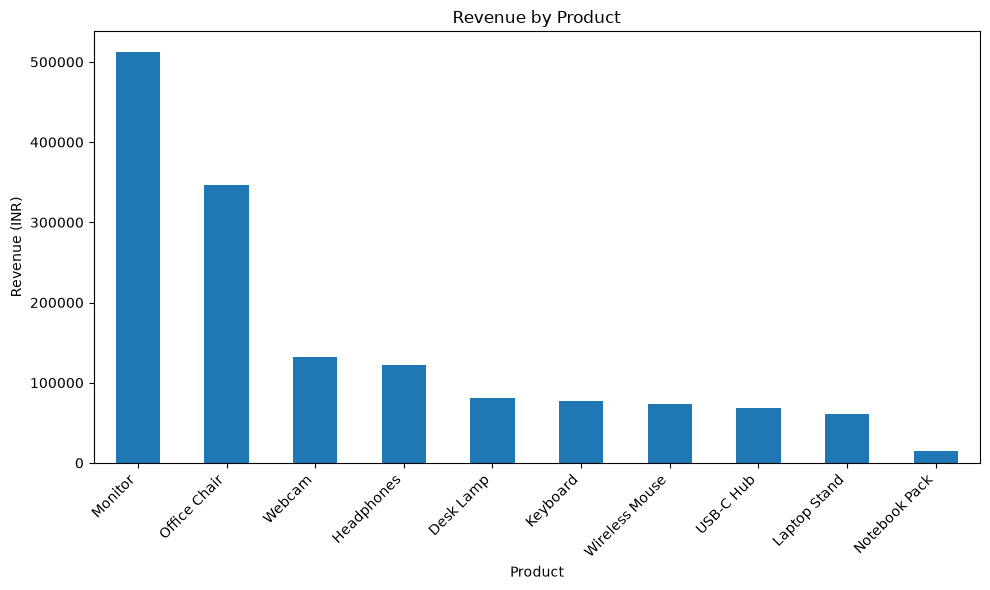

In [8]:

# Chart 1: Revenue by Product

import matplotlib.pyplot as plt

product_revenue = df.groupby("Product")["Revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
product_revenue.plot(kind="bar")
plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


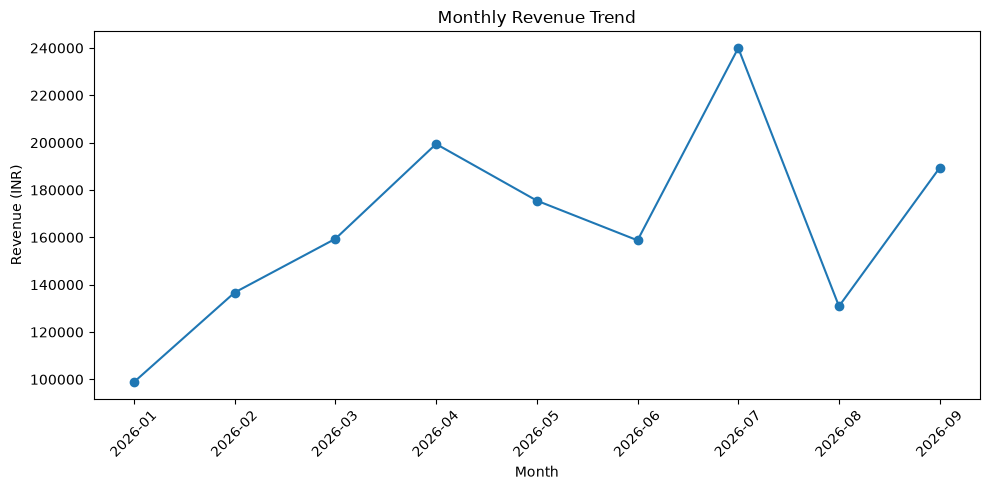

In [9]:

# Chart 2: Monthly Revenue Trend

df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_revenue = df.groupby("Month")["Revenue"].sum().sort_index()

plt.figure(figsize=(10, 5))
monthly_revenue.plot(kind="line", marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## Business Insights

1. Total revenue is ₹14,88,880 across 317 distinct orders.
2. The average order value is ₹4,696.78.
3. Monitor is the top revenue-generating product, contributing ₹5,12,510.
4. The West region has the highest revenue at ₹4,22,040.
5. Monthly revenue peaks in July 2026 and declines sharply in August.
6. One order has an Unknown region and one has an Unknown payment method. These records should be verified.
7. No duplicate rows or blank cells were detected in the initial dataset check.
